# Chapter 22: The Base Rate You Forgot

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** learn to ask one question of every percentage: "a percentage of *which group*?" You will work through a 100-parcel audit, a population of 10,000 split by a base rate, three rates that share a numerator but not a denominator, and the surprising mix inside a positive result.

The code cells are optional reading. Every result and picture is shown right below the code, so you can follow along without running anything. Everything here is fictional and chosen so every count is a whole number.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from fractions import Fraction as F

INK, TERRACOTTA, NAVY, TEAL, GREY, LIGHT = "#222222", "#c0563b", "#1f3a5f", "#2a8a85", "#777777", "#dddddd"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

def ft(x):
    x = F(x)
    return str(x.numerator) if x.denominator == 1 else f"{x.numerator}/{x.denominator}"

def pct(x, digits=1):
    return f"{float(x) * 100:.{digits}f}%"

def n(x):
    return f"{int(x):,}"

def draw_table(ax, cells, rows, cols, highlight=None, numerator=None, title=None):
    """Two by two count table with totals. highlight = ('row', i) or ('col', j): the denominator group."""
    for r in range(2):
        for c in range(2):
            inside = highlight is not None and ((highlight[0] == "row" and highlight[1] == r) or
                                                (highlight[0] == "col" and highlight[1] == c))
            ax.add_patch(Rectangle((c, 1 - r), 1, 1, facecolor="#e3efee" if inside else "white", edgecolor=GREY))
            is_num = numerator == (r, c)
            ax.text(c + 0.5, 1.5 - r, n(cells[r][c]), ha="center", va="center", fontsize=16,
                    color=TERRACOTTA if is_num else INK, fontweight="bold" if is_num else "normal")
    if highlight is not None:
        if highlight[0] == "row":
            ax.add_patch(Rectangle((0, 1 - highlight[1]), 2, 1, fill=False, edgecolor=TEAL, linewidth=3))
        else:
            ax.add_patch(Rectangle((highlight[1], 0), 1, 2, fill=False, edgecolor=TEAL, linewidth=3))
    for c, name in enumerate(cols):
        ax.text(c + 0.5, 2.08, name, ha="center", va="bottom")
    for r, name in enumerate(rows):
        ax.text(-0.06, 1.5 - r, name, ha="right", va="center")
    ax.text(2.5, 2.08, "Total", ha="center", va="bottom")
    ax.text(-0.06, -0.3, "Total", ha="right", va="center")
    for r in range(2):
        ax.text(2.5, 1.5 - r, n(sum(cells[r])), ha="center", va="center", color=TEAL if highlight == ("row", r) else GREY,
                fontweight="bold" if highlight == ("row", r) else "normal")
    for c in range(2):
        ax.text(c + 0.5, -0.3, n(cells[0][c] + cells[1][c]), ha="center", va="center",
                color=TEAL if highlight == ("col", c) else GREY, fontweight="bold" if highlight == ("col", c) else "normal")
    ax.text(2.5, -0.3, n(sum(map(sum, cells))), ha="center", va="center", color=GREY)
    if title:
        ax.text(1.0, 2.62, title, ha="center", va="bottom", fontsize=12.5, color=TERRACOTTA)
    ax.set_xlim(-0.95, 3.0); ax.set_ylim(-0.6, 3.0)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
print("Setup done.")

Setup done.


## Demonstration 1: Read the word "among"

**The question, in plain words:** In the same 100-parcel audit, why do 80% and 60% both come out right?

**The equation:**

$$P(D \mid A)$$

**What the symbols mean:**
- $D$ means the parcel is damaged; $A$ means the detector alerted.
- $P(D \mid A)$ is read "the probability of damage *given* an alert". The group after the bar supplies the denominator.
- The audit table has four cells: damaged and alerted 12, damaged and not alerted 3, sound and alerted 8, sound and not alerted 77.

**Predict first:** if 20 sound parcels set off alerts instead of 8, does the share of damaged parcels that alert change? Does the share of alerted parcels that are damaged change?

In [2]:
tp, fn, fp, tn = 12, 3, 8, 77
print(f"Table: damaged+alert {tp}, damaged+no alert {fn}, sound+alert {fp}, sound+no alert {tn}")
print(f"Total parcels: {tp} + {fn} + {fp} + {tn} = {tp + fn + fp + tn}")
print()
print(f"Among damaged parcels:  alert share = {tp}/({tp} + {fn}) = {tp}/{tp + fn} = {pct(F(tp, tp + fn))}")
print(f"Among alerted parcels:  damage share = {tp}/({tp} + {fp}) = {tp}/{tp + fp} = {pct(F(tp, tp + fp))}")
print(f"Among sound parcels:    false-alert share = {fp}/({fp} + {tn}) = {fp}/{fp + tn} = {pct(F(fp, fp + tn))}")
print()
fp2, tn2 = 20, 65     # the other menu value: 20 sound parcels alert (sound group stays at 85)
print("With 20 sound parcels alerting instead (sound group still 85):")
print(f"Among damaged parcels:  {tp}/({tp} + {fn}) = {tp}/{tp + fn} = {pct(F(tp, tp + fn))}  (unchanged)")
print(f"Among alerted parcels:  {tp}/({tp} + {fp2}) = {tp}/{tp + fp2} = {pct(F(tp, tp + fp2))}")
print(f"Among sound parcels:    {fp2}/({fp2} + {tn2}) = {fp2}/{fp2 + tn2} = {pct(F(fp2, fp2 + tn2))}")

Table: damaged+alert 12, damaged+no alert 3, sound+alert 8, sound+no alert 77
Total parcels: 12 + 3 + 8 + 77 = 100

Among damaged parcels:  alert share = 12/(12 + 3) = 12/15 = 80.0%
Among alerted parcels:  damage share = 12/(12 + 8) = 12/20 = 60.0%
Among sound parcels:    false-alert share = 8/(8 + 77) = 8/85 = 9.4%

With 20 sound parcels alerting instead (sound group still 85):
Among damaged parcels:  12/(12 + 3) = 12/15 = 80.0%  (unchanged)
Among alerted parcels:  12/(12 + 20) = 12/32 = 37.5%
Among sound parcels:    20/(20 + 65) = 20/85 = 23.5%


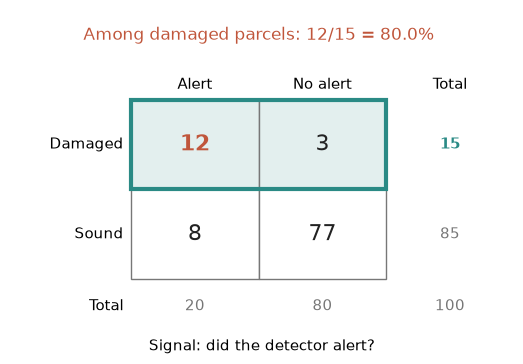

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
draw_table(ax, [[tp, fn], [fp, tn]], ["Damaged", "Sound"], ["Alert", "No alert"], highlight=("row", 0),
           numerator=(0, 0), title=f"Among damaged parcels: {tp}/{tp + fn} = {pct(F(tp, tp + fn))}")
ax.set_xlabel("Signal: did the detector alert?")
plt.show()

**What this shows:** all three shares use the same four cells. The word "among" picks a row or column to be the whole (outlined), and the bold cell is the part being counted. Same table, three different denominators, three different true statements: 80%, 37.5%, and 9.4%.

**Where it stops working:** this needs a completed audit where every parcel's damage was checked independently of the alert. If damage were judged *by* the alert itself, there would be no missed cases and the table would have no "damaged, no alert" cell. When someone quotes a percentage, ask "among which group?" before comparing it with any other percentage.

## Demonstration 2: Split the population first

**The question, in plain words:** Before anyone is tested, how lopsided are the two starting groups?

**The equation:**

$$10{,}000 - 100 = 9{,}900$$

**What the symbols mean:**
- The *base rate* is the share of a named population that has the condition before any result is known.
- Each square in the picture stands for 100 of the 10,000 fictional people.

**Predict first:** at a 10% base rate, how many squares are hatched, and how many people stand in the plain squares?

In [4]:
population = 10_000
base_rate = 0.01
sick = round(population * base_rate)
well = population - sick
print(f"With the condition: {base_rate * 100:.0f}% of {n(population)} = {n(sick)}")
print(f"Without the condition: {n(population)} - {n(sick)} = {n(well)}")
print(f"Ratio: {n(well)} / {n(sick)} = {well // sick} to 1")
print(f"Squares hatched: {n(sick)} / 100 = {sick // 100}")
print()
print("Other menu values:")
for br in [0.01, 0.02, 0.05, 0.10]:
    s = round(population * br)
    w = population - s
    print(f"{br * 100:>3.0f}%: {n(s):>5} with, {n(population)} - {n(s)} = {n(w)} without, "
          f"{w / s:.0f} to 1, {s // 100} hatched square{'' if s // 100 == 1 else 's'}")

With the condition: 1% of 10,000 = 100
Without the condition: 10,000 - 100 = 9,900
Ratio: 9,900 / 100 = 99 to 1
Squares hatched: 100 / 100 = 1

Other menu values:
  1%:   100 with, 10,000 - 100 = 9,900 without, 99 to 1, 1 hatched square
  2%:   200 with, 10,000 - 200 = 9,800 without, 49 to 1, 2 hatched squares
  5%:   500 with, 10,000 - 500 = 9,500 without, 19 to 1, 5 hatched squares
 10%: 1,000 with, 10,000 - 1,000 = 9,000 without, 9 to 1, 10 hatched squares


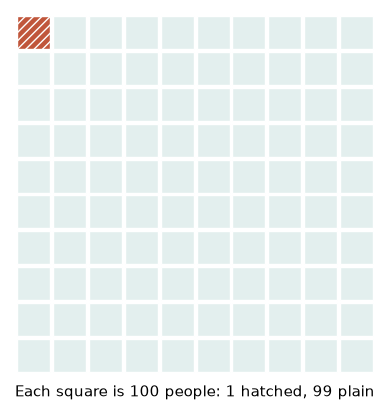

In [5]:
cells_with = sick // 100
fig, ax = plt.subplots(figsize=(4.8, 4.8))
for k in range(100):
    r, col = divmod(k, 10)
    has = k < cells_with
    ax.add_patch(Rectangle((col, 9 - r), 0.92, 0.92, facecolor=TERRACOTTA if has else "#e3efee",
                           edgecolor="white", hatch="////" if has else None))
ax.set_xlim(-0.2, 10.1); ax.set_ylim(-0.2, 10.1); ax.set_aspect("equal")
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel(f"Each square is 100 people: {cells_with} hatched, {100 - cells_with} plain")
plt.show()

**What this shows:** the base rate cuts the population into two groups before any test is applied. Every later rate acts inside one of those groups, so their sizes decide how many people each rate can touch. At 1%, the group without the condition is 99 times as large.

**Where it stops working:** this is a fictional population with a stated base rate, not any real condition or group. The split fails if the base rate belongs to a different population than the one being tested. Before reading any test or alert result, write down the two starting counts.

## Demonstration 3: Three rates, three denominators

**The question, in plain words:** The same 90 true positives sit in two different fractions. What makes the fractions different?

**The equations:**

$$\text{sensitivity} = 90/(90 + 10) \qquad\qquad \text{positive predictive value} = 90/(90 + 495)$$

**What the symbols mean:**
- *Sensitivity* looks across the condition row: of people who have it, how many test positive.
- The *false-positive rate* looks across the no-condition row.
- *Positive predictive value* looks down the positive column: of the positive results, how many are true.

**Predict first:** double the fictional population to 20,000. Will the positive predictive value change?

In [6]:
for k, label in [(1, "10,000"), (2, "20,000")]:
    tp, fn, fp, tn = 90 * k, 10 * k, 495 * k, 9405 * k
    print(f"Population {label}: true pos {n(tp)}, false neg {n(fn)}, false pos {n(fp)}, true neg {n(tn)}  (total {n(tp + fn + fp + tn)})")
    print(f"  sensitivity     = {n(tp)}/({n(tp)} + {n(fn)}) = {n(tp)}/{n(tp + fn)} = {ft(F(tp, tp + fn))} = {pct(F(tp, tp + fn))}")
    print(f"  false-positive  = {n(fp)}/({n(fp)} + {n(tn)}) = {n(fp)}/{n(fp + tn)} = {ft(F(fp, fp + tn))} = {pct(F(fp, fp + tn))}")
    print(f"  positive pred.  = {n(tp)}/({n(tp)} + {n(fp)}) = {n(tp)}/{n(tp + fp)} = {ft(F(tp, tp + fp))} = {pct(F(tp, tp + fp))}")

Population 10,000: true pos 90, false neg 10, false pos 495, true neg 9,405  (total 10,000)
  sensitivity     = 90/(90 + 10) = 90/100 = 9/10 = 90.0%
  false-positive  = 495/(495 + 9,405) = 495/9,900 = 1/20 = 5.0%
  positive pred.  = 90/(90 + 495) = 90/585 = 2/13 = 15.4%
Population 20,000: true pos 180, false neg 20, false pos 990, true neg 18,810  (total 20,000)
  sensitivity     = 180/(180 + 20) = 180/200 = 9/10 = 90.0%
  false-positive  = 990/(990 + 18,810) = 990/19,800 = 1/20 = 5.0%
  positive pred.  = 180/(180 + 990) = 180/1,170 = 2/13 = 15.4%


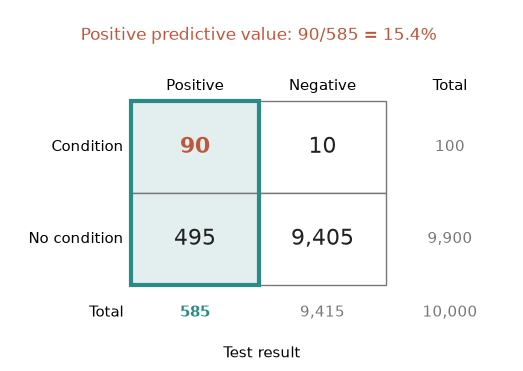

In [7]:
tp, fn, fp, tn = 90, 10, 495, 9405
fig, ax = plt.subplots(figsize=(6.5, 4.3))
draw_table(ax, [[tp, fn], [fp, tn]], ["Condition", "No condition"], ["Positive", "Negative"], highlight=("col", 0),
           numerator=(0, 0), title=f"Positive predictive value: {tp}/{tp + fp} = {pct(F(tp, tp + fp))}")
ax.set_xlabel("Test result")
plt.show()

**What this shows:** each rate outlines a different set of cells as its whole. The 90 true positives stay the same, but divided by the condition row (100) they give 90%, and divided by the positive column (585) they give about 15.4%. Doubling the population doubles both the numerator and denominator, so every fraction stays the same.

**Where it stops working:** scaling works only when every cell is multiplied by the same factor. Changing the base rate is a different change and moves the fractions. Whenever you read a rate, name its denominator group out loud: across a row, or down a column.

## Demonstration 4: The positive column is a mixture

**The question, in plain words:** With a test that catches 90% of cases, why are most positive results false here?

**The equation:**

$$P(\text{condition} \mid \text{positive}) = 90/585$$

**What the symbols mean:**
- Sensitivity is held at 90%.
- The *false-positive rate* is the share of people without the condition who still test positive.
- $P(\text{condition} \mid \text{positive})$ is the share of positive results that are true positives.

**Predict first:** keep the false-positive rate at 5% and move the base rate from 1% to 2%. Does the true share among positives roughly double, or less than double?

In [8]:
def model(base_rate, fpr, population=10_000):
    sick = round(population * base_rate)
    well = population - sick
    tp = round(0.9 * sick)
    fp = round(fpr * well)
    return sick, well, tp, fp

sick, well, tp, fp = model(0.01, 0.05)
pos = tp + fp
print(f"With the condition: 1% of 10,000 = {n(sick)}; without: {n(well)}")
print(f"True positives:  90% of {n(sick)} = {n(tp)}")
print(f"False positives: 5% of {n(well)} = {n(fp)}")
print(f"All positives: {n(tp)} + {n(fp)} = {n(pos)}")
print(f"P(condition | positive) = {n(tp)}/{n(pos)} = {ft(F(tp, pos))} = {pct(F(tp, pos))}")
print()
print("All eight menu states (sensitivity fixed at 90%):")
for fpr in (0.05, 0.01):
    for br in (0.01, 0.02, 0.05, 0.10):
        s, w, t, f = model(br, fpr)
        print(f"base {br * 100:>2.0f}%, false-positive {fpr * 100:.0f}%: {t}/({t} + {n(f)}) = {t}/{n(t + f)} = {ft(F(t, t + f))} = {pct(F(t, t + f))}")

With the condition: 1% of 10,000 = 100; without: 9,900
True positives:  90% of 100 = 90
False positives: 5% of 9,900 = 495
All positives: 90 + 495 = 585
P(condition | positive) = 90/585 = 2/13 = 15.4%

All eight menu states (sensitivity fixed at 90%):
base  1%, false-positive 5%: 90/(90 + 495) = 90/585 = 2/13 = 15.4%
base  2%, false-positive 5%: 180/(180 + 490) = 180/670 = 18/67 = 26.9%
base  5%, false-positive 5%: 450/(450 + 475) = 450/925 = 18/37 = 48.6%
base 10%, false-positive 5%: 900/(900 + 450) = 900/1,350 = 2/3 = 66.7%
base  1%, false-positive 1%: 90/(90 + 99) = 90/189 = 10/21 = 47.6%
base  2%, false-positive 1%: 180/(180 + 98) = 180/278 = 90/139 = 64.7%
base  5%, false-positive 1%: 450/(450 + 95) = 450/545 = 90/109 = 82.6%
base 10%, false-positive 1%: 900/(900 + 90) = 900/990 = 10/11 = 90.9%


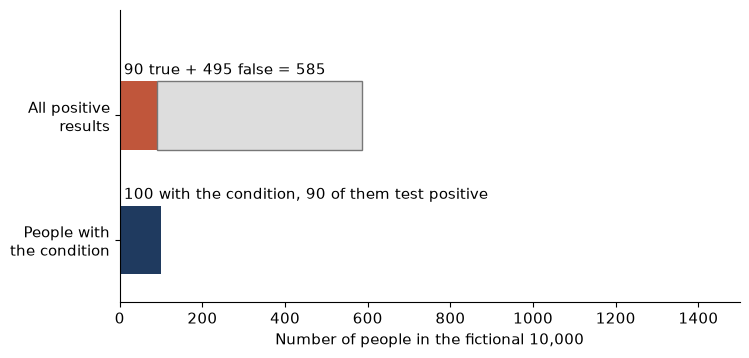

In [9]:
sick, well, tp, fp = model(0.01, 0.05)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh([1], [tp], color=TERRACOTTA, height=0.55)
ax.barh([1], [fp], left=[tp], color=LIGHT, height=0.55, edgecolor=GREY)
ax.barh([0], [sick], color=NAVY, height=0.55)
ax.set_yticks([0, 1]); ax.set_yticklabels(["People with\nthe condition", "All positive\nresults"])
ax.set_xlim(0, 1500); ax.set_ylim(-0.5, 1.85)
ax.text(10, 1.33, f"{n(tp)} true + {n(fp)} false = {n(tp + fp)}", fontsize=10.5)
ax.text(10, 0.33, f"{n(sick)} with the condition, {tp} of them test positive", fontsize=10.5)
ax.set_xlabel("Number of people in the fictional 10,000")
plt.show()

**What this shows:** positive results come from both rows. A small rate (5%) applied to the huge condition-free row gives 495 false positives, which outnumber the 90 true positives that a large rate (90%) produces from the small condition row. Moving the base rate from 1% to 2% takes the true share from 15.4% to 26.9%: more, but less than double.

**Where it stops working:** these are fictional rates on a fictional 10,000 people, chosen so every count is whole. Sensitivity and the false-positive rate are held fixed while the base rate moves. No real test, diagnosis or risk is described. When a result is positive, count true and false positives in a stated population before deciding what it means.

## Practice

**1.** An audit has 15 damaged parcels with 12 alerts, and 85 sound parcels with 28 alerts. What share of alerted parcels are damaged?

<details><summary>Show answer</summary>

Alerted parcels: $12 + 28 = 40$.
Damaged among alerted: $12/40 = 30\%$.
The share of damaged parcels that alert is still $12/15 = 80\%$. Same table, different denominator.

</details>

**2.** With a 5% base rate in 10,000 people, how many people are without the condition?

<details><summary>Show answer</summary>

With the condition: $5\% \times 10{,}000 = 500$.
Without: $10{,}000 - 500 = 9{,}500$.

</details>

**3.** With a 1% base rate, 90% sensitivity and a 1% false-positive rate, what share of positive results are true positives?

<details><summary>Show answer</summary>

With the condition: $1\% \times 10{,}000 = 100$. Without: $9{,}900$.
True positives: $90\% \times 100 = 90$.
False positives: $1\% \times 9{,}900 = 99$.
Share: $90/(90 + 99) = 90/189 = 10/21$, about $47.6\%$.

</details>